# Practical 10: Ensemble Learning (Random Forest and Boosting)

**Aim:** Compare ensemble models (Random Forest, AdaBoost, Gradient Boosting) with a single Decision Tree as the baseline.

**Dataset:** Breast Cancer (569 patients, 30 features). Built into scikit-learn.

- **Bagging (Random Forest):** many trees trained in parallel on random samples, then they vote.
- **Boosting (AdaBoost, Gradient Boosting):** trees trained one after another, each one fixing the mistakes of the previous.

**Steps:** 1) Load and split  2) Train all models  3) Compare  4) Feature importance  5) Effect of the number of trees

## Step 1: Load and split

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = 1 - data.target          # 1 = malignant, 0 = benign

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

# Tree-based models do NOT need scaling
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (426, 30)  Test: (143, 30)


## Step 2: Train and compare all models

In [2]:
models = {
    "Decision Tree (baseline)": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, random_state=42),
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    cv = cross_val_score(model, X, y, cv=5).mean()     # average accuracy over 5 splits
    rows.append([name,
                 round(accuracy_score(y_test, pred), 3),
                 round(precision_score(y_test, pred), 3),
                 round(recall_score(y_test, pred), 3),
                 round(f1_score(y_test, pred), 3),
                 round(roc_auc_score(y_test, prob), 3),
                 round(cv, 3)])

table = pd.DataFrame(rows, columns=["Model", "Accuracy", "Precision", "Recall", "F1", "AUC", "CV accuracy"])
table

,Model,Accuracy,Precision,Recall,F1,AUC,CV accuracy
0,Decision Tree (baseline),0.958,0.98,0.906,0.941,0.947,0.917
1,Random Forest,0.958,1.00,0.887,0.940,0.995,0.954
2,AdaBoost,0.972,1.00,0.925,0.961,0.995,0.977
3,Gradient Boosting,0.965,1.00,0.906,0.950,0.996,0.961


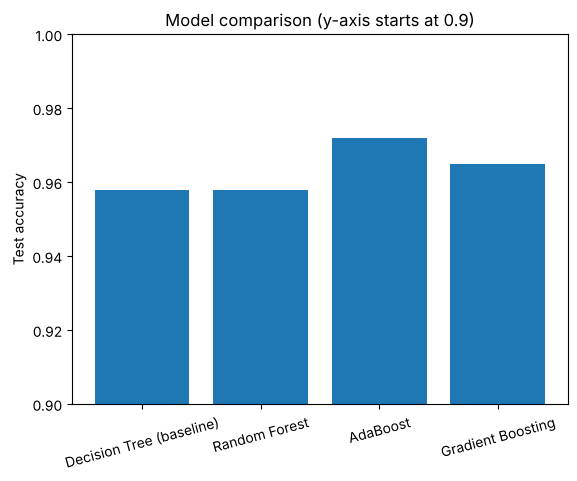

In [3]:
plt.bar(table["Model"], table["Accuracy"])
plt.ylim(0.9, 1.0)
plt.xticks(rotation=15)
plt.ylabel("Test accuracy")
plt.title("Model comparison (y-axis starts at 0.9)")
plt.show()

**How to read (be honest in the viva):**
- On this single test split (143 patients, one patient is 0.7%) the accuracies are close: tree 0.958, Random Forest 0.958, Gradient Boosting 0.965, AdaBoost 0.972. Random Forest only ties the tree, so do not claim a big win from accuracy alone.
- The **clearer evidence** is in the other columns: the ensembles have a much higher **AUC** (about 0.995 vs 0.947 for the tree), and a higher **CV accuracy** (about 0.95 to 0.98 vs 0.92 for the tree). CV accuracy averages 5 different splits, so it is more trustworthy than one split.

## Step 3: Feature importance
Which features did the Random Forest use the most?

worst perimeter         0.150
worst area              0.121
worst concave points    0.103
mean concave points     0.101
worst radius            0.082
mean perimeter          0.062
mean radius             0.061
mean area               0.048
mean concavity          0.040
area error              0.030
dtype: float64


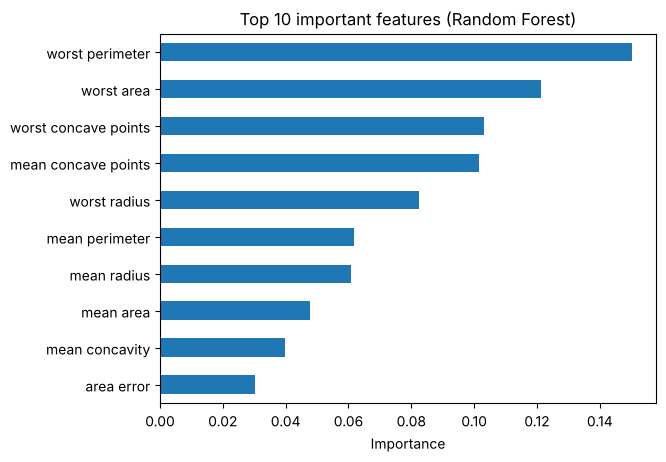

In [4]:
forest = models["Random Forest"]
importance = pd.Series(forest.feature_importances_, index=X.columns)
top10 = importance.sort_values(ascending=False).head(10)
print(top10.round(3))

top10.sort_values().plot(kind="barh")
plt.xlabel("Importance")
plt.title("Top 10 important features (Random Forest)")
plt.show()

**How to read:** a longer bar means that feature helped the trees split the data better. Size measures such as `worst perimeter`, `worst area` and `concave points` matter most. Importance shows **how much** a feature matters, not whether it raises or lowers the risk.

## Step 4: Effect of the number of trees

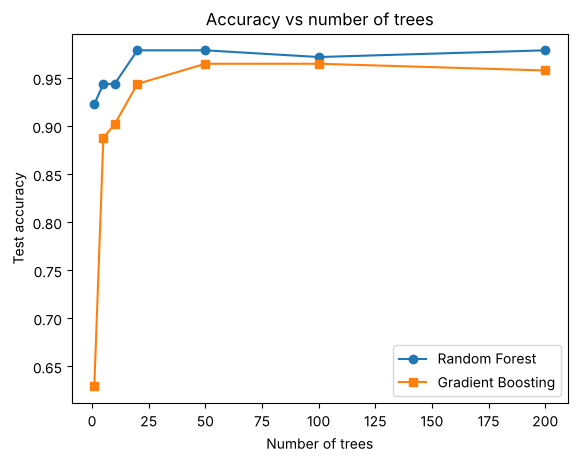

In [5]:
n_trees = [1, 5, 10, 20, 50, 100, 200]
rf_scores = []
gb_scores = []

for n in n_trees:
    rf = RandomForestClassifier(n_estimators=n, random_state=0).fit(X_train, y_train)
    gb = GradientBoostingClassifier(n_estimators=n, random_state=0).fit(X_train, y_train)
    rf_scores.append(rf.score(X_test, y_test))
    gb_scores.append(gb.score(X_test, y_test))

plt.plot(n_trees, rf_scores, marker="o", label="Random Forest")
plt.plot(n_trees, gb_scores, marker="s", label="Gradient Boosting")
plt.xlabel("Number of trees")
plt.ylabel("Test accuracy")
plt.title("Accuracy vs number of trees")
plt.legend()
plt.show()

**How to read:** accuracy rises as trees are added and then levels off. After that point, more trees only cost time. The Random Forest curve does **not** drop when trees are added (bagging is hard to overfit). Gradient Boosting starts lower with 1 tree (with the default small learning rate, one tree barely changes anything) and needs more trees. Small wiggles are just noise from the small test set.

## Step 5: Out-of-bag (OOB) score

In [6]:
# Each tree is trained on a random sample; the rows it did NOT see are used to test it
rf_oob = RandomForestClassifier(n_estimators=200, oob_score=True, random_state=42)
rf_oob.fit(X_train, y_train)
print("OOB accuracy :", round(rf_oob.oob_score_, 3))
print("Test accuracy:", round(rf_oob.score(X_test, y_test), 3))

OOB accuracy : 0.953
Test accuracy: 0.958


The OOB score is close to the test score, so it gives a free validation estimate without a separate validation set.

## Conclusion
All three ensembles beat the single Decision Tree in AUC and cross-validated accuracy (AdaBoost was best in my run); on the single test split the differences in accuracy are small. Bagging mainly reduces variance, boosting mainly reduces bias. Ensembles are less easy to explain and slower to train than one tree.

---
# Viva Questions and Answers

## A. Concept questions

**Q1. What is ensemble learning?**
Combining multiple models (weak learners) to get a better, more stable model than any single one.

**Q2. Types of ensemble methods?**
Bagging (Random Forest), Boosting (AdaBoost, Gradient Boosting, XGBoost), Stacking and Voting.

**Q3. What is bagging?**
Bootstrap Aggregating: train many models on random samples drawn with replacement, then average (regression) or vote (classification). It reduces **variance**.

**Q4. What is Random Forest?**
An ensemble of decision trees built with bagging **plus random feature selection at each split**, which de-correlates the trees. The final output is the majority vote.

**Q5. Why does Random Forest beat a single tree?**
A single deep tree overfits (high variance). Averaging many different trees cancels individual errors and reduces variance.

**Q6. What is a bootstrap sample and OOB error?**
A bootstrap sample is drawn with replacement from the training data (about 63% unique rows). The remaining ~37% (out-of-bag) rows give a free error estimate (`oob_score=True`).

**Q7. What is boosting?**
Sequentially training weak learners where each tries to correct the errors of the previous ones, giving more weight to misclassified examples. It mainly reduces **bias**.

**Q8. AdaBoost vs Gradient Boosting?**
AdaBoost re-weights misclassified samples and combines learners with weights. Gradient Boosting fits each new tree to the residual errors (the negative gradient of the loss).

**Q9. Key hyperparameters of Random Forest?**
`n_estimators`, `max_depth`, `max_features`, `min_samples_split`, `min_samples_leaf`.

**Q10. Key hyperparameters of boosting?**
`n_estimators`, `learning_rate` (smaller rate needs more trees), `max_depth`, `subsample`.

**Q11. Which one is more prone to overfitting?**
Boosting, especially with many rounds and a high learning rate. Random Forest is more robust.

**Q12. What is a weak learner?**
A model only slightly better than random guessing, such as a shallow tree (stump).

**Q13. Is scaling required for tree ensembles?**
No, trees split on thresholds and are scale-invariant.

**Q14. How is feature importance calculated?**
By the total decrease in impurity (Gini or entropy) contributed by splits on that feature, averaged over all trees.

**Q15. What is a baseline model and why use it?**
A simple model used as a reference. If a complex model cannot beat it, the added complexity is not justified. The Dummy model is the lowest bar; the single decision tree is the practical baseline.

**Q16. What are the disadvantages of ensembles?**
Less interpretable, higher computation and memory, longer training time.

**Q17. What is a decision tree and what is Gini impurity?**
A tree-shaped model that splits data on feature thresholds. Gini = $1-\sum p_i^2$; it is 0 for a pure node, and the best split reduces it the most.

**Q18. What is stacking?**
Training a meta-model on the predictions of several different base models.

**Q19. Bagging vs boosting?**
Bagging: parallel, independent trees on bootstrap samples, reduces variance. Boosting: sequential trees, each fixing the previous errors, reduces bias.

**Q20. Why does a single decision tree reach 100% training accuracy?**
An unrestricted tree keeps splitting until every leaf is pure, memorising the training data: overfitting.

**Q21. Why is `max_features` important in Random Forest?**
Using only a random subset of features at each split forces trees to be different (de-correlated), which makes averaging more effective.

**Q22. What is XGBoost?**
An optimised, regularised implementation of gradient boosting that is fast and widely used.

**Q23. How does a Random Forest do regression?**
Each tree predicts a number, and the forest averages them.

**Q24. Can feature importance be misleading?**
Yes: it is biased toward features with many unique values, splits importance across correlated features, and gives no direction of effect. Permutation importance is a more reliable alternative.

## B. Questions about the graphs

**G1. What does the feature importance bar plot show?**
The contribution of each feature to reducing impurity across all trees, normalised to sum to 1. Long bars (for example worst perimeter, worst concave points) mean influential features.

**G2. Can importance tell the direction of the effect?**
No, only the strength.

**G3. What does the model comparison bar chart show?**
Test metrics for each model. The ensembles are slightly higher than the baseline tree in accuracy and clearly higher in AUC, meaning combining many learners improves ranking quality. Be honest that accuracy differences on a 143-sample test set are small.

**G3b. Your Random Forest had the same accuracy as the single tree. Does that mean it is no better?**
Not necessarily. On one 143-sample test split, accuracy is noisy (one patient = 0.7%). The Random Forest has a much higher AUC (0.995 vs 0.947) and a higher cross-validated accuracy (0.953 vs 0.926), which are more reliable measures.

**G4. What does the accuracy-vs-number-of-trees plot show?**
For Random Forest accuracy rises then plateaus, so more trees does not overfit. For boosting, test accuracy plateaus (and can drop with too many rounds) while training accuracy keeps rising.

## C. Code questions

**C1. Why `stratify=y`?**
To keep the same class proportion in train and test.

**C2. What does `n_estimators` mean?**
The number of trees in the ensemble.

**C3. What does `predict_proba` return for a forest?**
The average of the class probabilities predicted by all trees.

**C4. Why is `random_state` set?**
Bootstrap sampling and feature selection are random; the seed makes results reproducible.